# Task 4: Real-World Retail Analytics Project
## Customer Segmentation and Sales/Demand Analysis

**Objective:** Analyze online retail transactions to identify valuable customer groups, understand sales patterns, and estimate product demand using historical data.

**Dataset:** UCI Online Retail dataset (transaction-level data from a UK-based online retailer).

**Methods covered:**
- Data cleaning and transaction filtering
- Exploratory sales analysis
- RFM (Recency, Frequency, Monetary) customer segmentation
- Monthly sales trends
- Product-level demand summaries
- A simple baseline forecast using a time-based train/test split

> This is an educational analytics project. Forecasts are baseline estimates, not production-grade inventory recommendations.

In [1]:
# Install/import dependencies (usually already available in Colab)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.request import urlopen
from io import BytesIO
import zipfile
import os
import warnings

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Load the dataset

In [2]:
# UCI dataset archive. Extract by inspecting filenames rather than assuming a fixed path.
DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = urlopen(DATA_URL, timeout=60)
archive_bytes = BytesIO(response.read())

with zipfile.ZipFile(archive_bytes) as z:
    candidates = [name for name in z.namelist()
                  if name.lower().endswith((".xlsx", ".xls"))]
    print("Archive files:", z.namelist())
    if not candidates:
        raise FileNotFoundError("No Excel dataset found in the downloaded archive.")
    data_file = candidates[0]
    with z.open(data_file) as f:
        df = pd.read_excel(f)

print("Loaded file:", data_file)
print("Dataset shape:", df.shape)
df.head()

Archive files: ['Online Retail.xlsx']
Loaded file: Online Retail.xlsx
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Understand and clean the data

In [3]:
print(df.info())
display(df.isna().sum().sort_values(ascending=False))
display(df.describe(include="all").T.head(12))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


,0
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Normalize column names and remove rows that cannot contribute to valid sales analysis
df.columns = [str(c).strip().replace(" ", "") for c in df.columns]

required = {"InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Expected columns missing: {missing}")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.dropna(subset=["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice"])
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["CustomerID"] = df["CustomerID"].astype("string")

# Exclude cancellations/returns and non-positive quantities or prices for sales analysis
sales = df[
    (~df["InvoiceNo"].str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
print("Rows before cleaning:", len(df))
print("Rows after filtering:", len(sales))
sales.head()

Rows before cleaning: 541909
Rows after filtering: 530104


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 3. Exploratory sales analysis

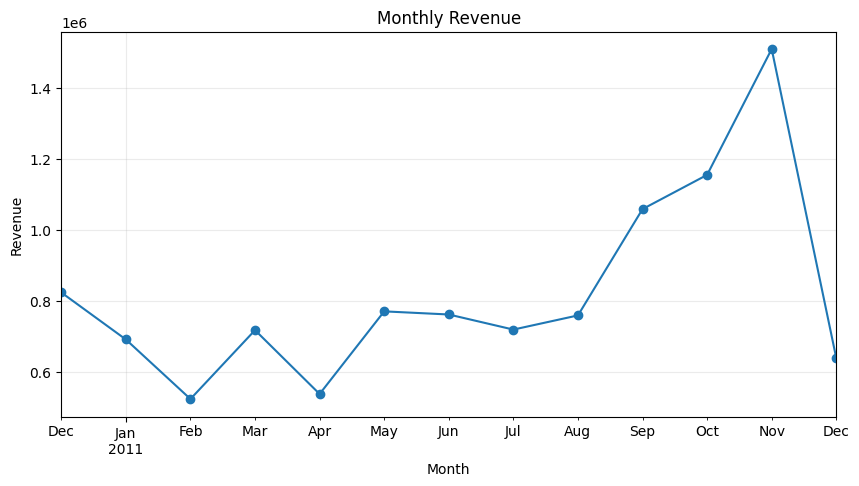

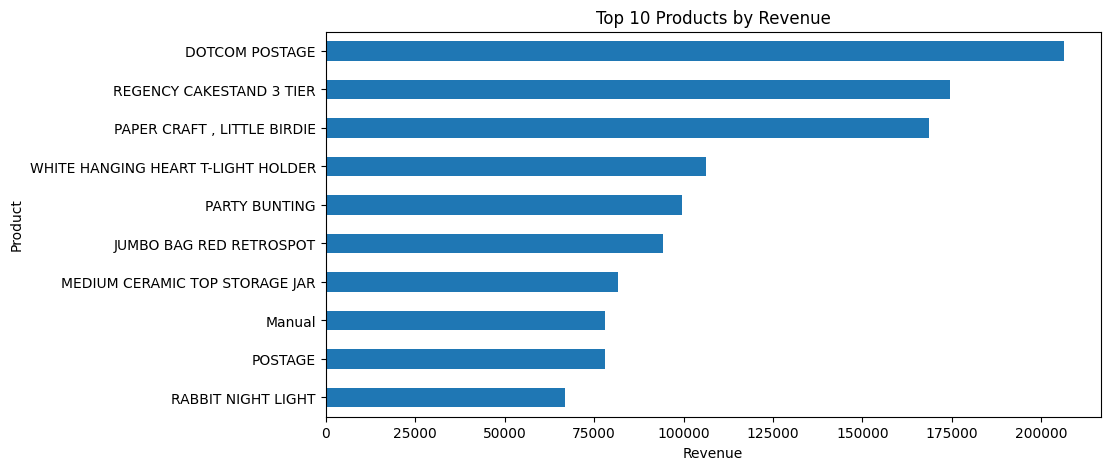

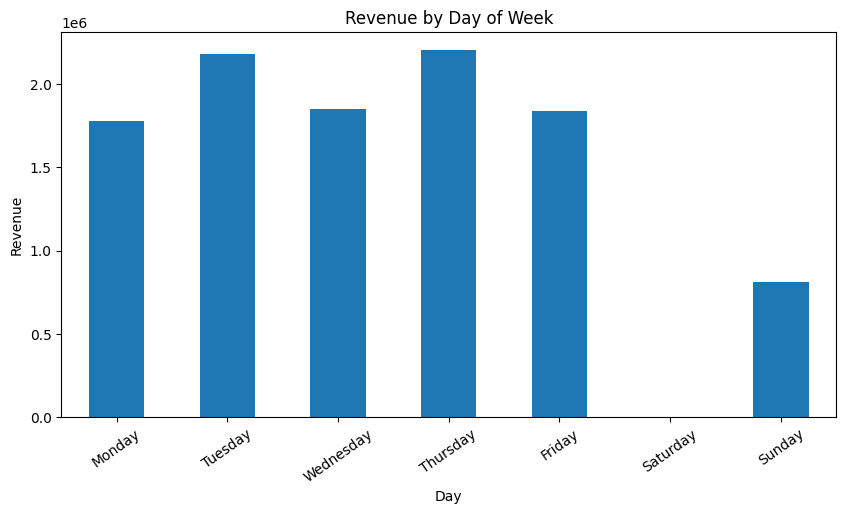

In [5]:
# Revenue by month
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
monthly_revenue = sales.groupby("Month")["Revenue"].sum().sort_index()

monthly_revenue.plot(marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(alpha=0.25)
plt.show()

# Top 10 products by revenue
top_products = (sales.groupby("Description")["Revenue"]
                .sum().sort_values(ascending=False).head(10))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.show()

# Revenue by weekday
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()
weekday_revenue = sales.groupby("Weekday")["Revenue"].sum().reindex(weekday_order)
weekday_revenue.plot(kind="bar")
plt.title("Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.xticks(rotation=35)
plt.show()

## 4. RFM customer segmentation

RFM features:
- **Recency:** days since the customer's latest purchase
- **Frequency:** number of distinct invoices
- **Monetary:** total customer revenue

The reference date is set to one day after the latest transaction in this dataset.

In [6]:
customer_sales = sales.dropna(subset=["CustomerID"]).copy()
reference_date = customer_sales["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_sales.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

# Quantile-based scores. Duplicated quantile edges can occur in some datasets;
# rank(method="first") ensures bins can still be formed.
rfm["R_score"] = pd.qcut(rfm["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

rfm["RFM_score"] = rfm[["R_score", "F_score", "M_score"]].astype(str).agg("".join, axis=1)

def assign_segment(row):
    if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
        return "High Value"
    elif row["R_score"] >= 3 and row["F_score"] >= 2:
        return "Loyal / Active"
    elif row["R_score"] <= 2 and row["F_score"] >= 2:
        return "At Risk"
    else:
        return "Needs Attention"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)
display(rfm.head())
display(rfm.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).sort_values("Total_Revenue", ascending=False))

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,4,114,Needs Attention
12347.0,2,7,4310.00,4,4,4,444,High Value
12348.0,75,4,1797.24,2,3,4,234,At Risk
12349.0,19,1,1757.55,3,1,4,314,Needs Attention
12350.0,310,1,334.40,1,1,2,112,Needs Attention


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Segment,,,,,
High Value,1314,16.965753,9.388128,4942.317337,6494204.981
At Risk,1337,146.364248,2.841436,1068.457152,1428527.212
Loyal / Active,602,22.998339,2.179402,830.968123,500242.810
Needs Attention,1085,156.309677,1.000000,450.168572,488432.901


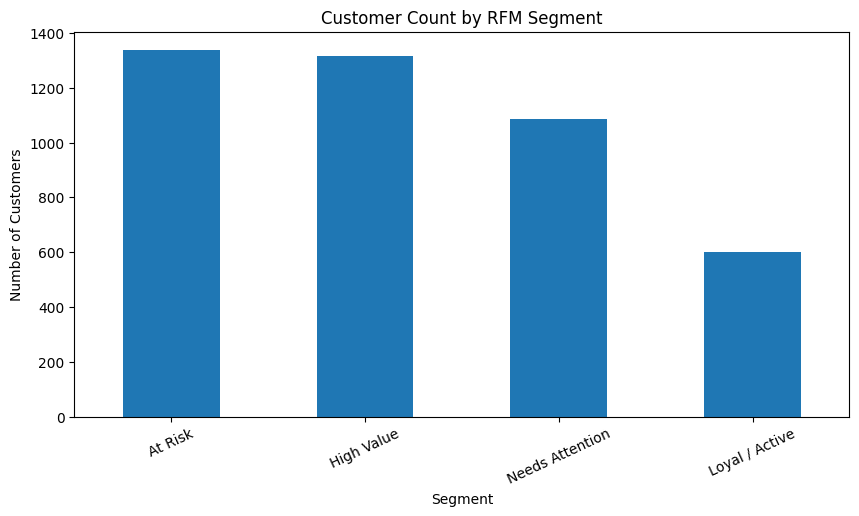

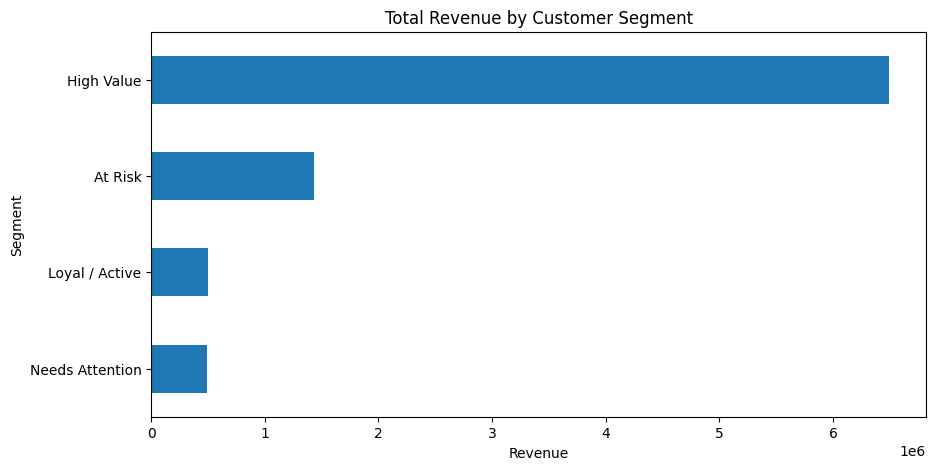

In [7]:
segment_counts = rfm["Segment"].value_counts()
segment_counts.plot(kind="bar")
plt.title("Customer Count by RFM Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.show()

rfm.groupby("Segment")["Monetary"].sum().sort_values().plot(kind="barh")
plt.title("Total Revenue by Customer Segment")
plt.xlabel("Revenue")
plt.ylabel("Segment")
plt.show()

## 5. Product demand summary

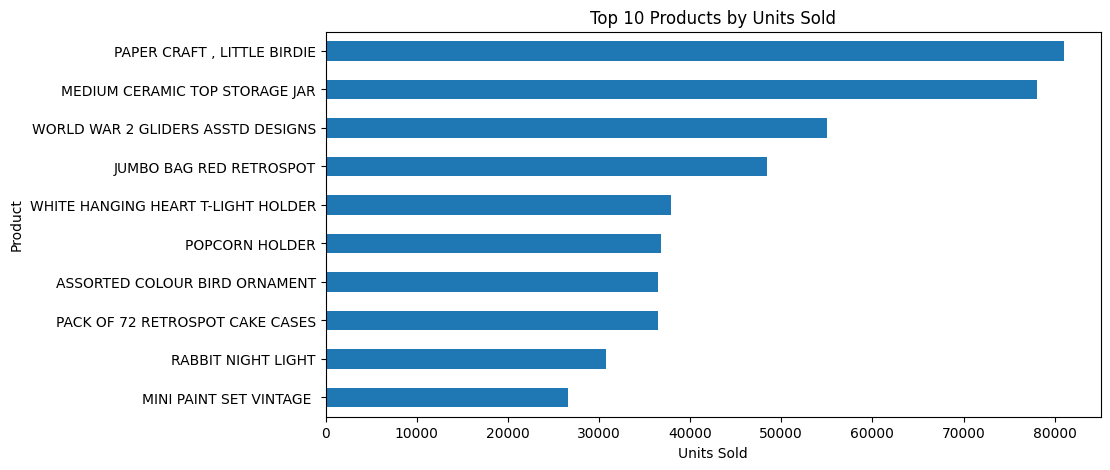

,Month,StockCode,Description,Quantity
0,2010-12-01,10002,INFLATABLE POLITICAL GLOBE,251
2808,2011-01-01,10002,INFLATABLE POLITICAL GLOBE,340
5391,2011-02-01,10002,INFLATABLE POLITICAL GLOBE,52
7799,2011-03-01,10002,INFLATABLE POLITICAL GLOBE,28
10317,2011-04-01,10002,INFLATABLE POLITICAL GLOBE,189


In [8]:
# Demand proxy: total units sold per product per month
product_monthly = (sales.groupby(["Month", "StockCode", "Description"], as_index=False)
                   ["Quantity"].sum()
                   .sort_values(["StockCode", "Month"]))

top_demand_products = (sales.groupby("Description")["Quantity"]
                       .sum().sort_values(ascending=False).head(10))
top_demand_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.show()

display(product_monthly.head())

## 6. Baseline monthly revenue forecast

A simple naive baseline predicts each test month's revenue using the previous month's actual revenue. This provides a transparent benchmark for a small time-series project.

,Actual,Naive_Forecast
Month,,
2011-10-01,1154979.30,1058590.172
2011-11-01,1509496.33,1154979.300
2011-12-01,638792.68,1509496.330


MAE: 440,536.60
RMSE: 545,618.31


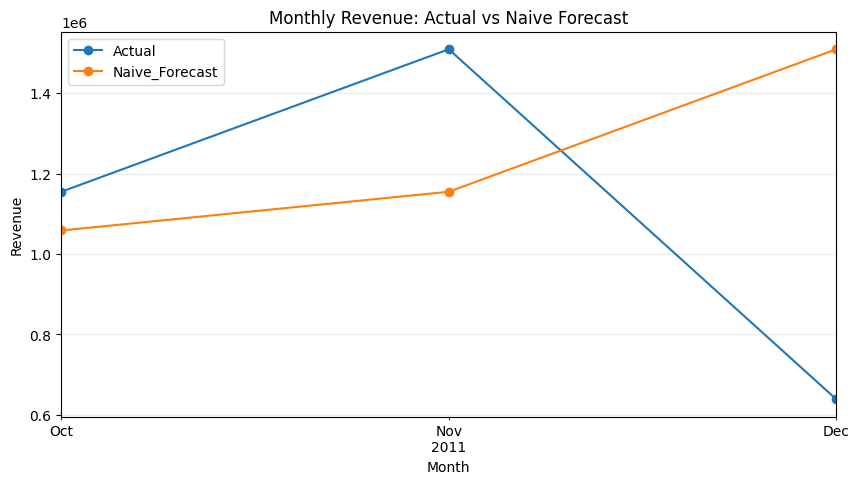

In [9]:
monthly = monthly_revenue.asfreq("MS").fillna(0)
if len(monthly) < 4:
    raise ValueError("Not enough monthly observations for a time-based train/test split.")

split = max(2, int(len(monthly) * 0.8))
train = monthly.iloc[:split]
test = monthly.iloc[split:]

# Naive forecast: previous observed month's revenue
forecast = monthly.shift(1).loc[test.index]
forecast = forecast.fillna(train.iloc[-1])

comparison = pd.DataFrame({"Actual": test, "Naive_Forecast": forecast})
display(comparison)

mae = (comparison["Actual"] - comparison["Naive_Forecast"]).abs().mean()
rmse = np.sqrt(((comparison["Actual"] - comparison["Naive_Forecast"]) ** 2).mean())
print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")

comparison.plot(marker="o")
plt.title("Monthly Revenue: Actual vs Naive Forecast")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(alpha=0.25)
plt.show()

## 7. Export results
Save the cleaned transaction data and RFM customer segments for use in a dashboard or report.

In [10]:
sales.to_csv("cleaned_online_retail.csv", index=False)
rfm.to_csv("customer_rfm_segments.csv")
comparison.to_csv("monthly_revenue_forecast_baseline.csv")

print("Exported:")
print("- cleaned_online_retail.csv")
print("- customer_rfm_segments.csv")
print("- monthly_revenue_forecast_baseline.csv")

Exported:
- cleaned_online_retail.csv
- customer_rfm_segments.csv
- monthly_revenue_forecast_baseline.csv


## 8. Project summary
This notebook demonstrates an end-to-end retail analytics workflow: cleaning transaction records, exploring sales, segmenting customers with RFM, summarizing product demand, and evaluating a simple monthly revenue forecast. The outputs can support customer engagement and inventory planning, while more advanced forecasting and validation can be added later.